# 04 — Benchmark de TTA (Part IV)
Sources : `results/tta_<bb>_{summary,mcnemar,friedman}`, `results/hp_<bb>.json`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, F = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
def fig(name):
    p = F / f"{name}.png"
    display(Image(str(p))) if p.exists() else print("missing figure:", p.name)
def csv(name):
    p = R / name
    return pd.read_csv(p) if p.exists() else print("missing table:", p.name)

In [2]:
for bb in ['vit_s16', 'resnet50']:
    h = json.load(open(R / f'hp_{bb}.json')) if (R / f'hp_{bb}.json').exists() else {}
    display(Markdown(f'**HP sélectionnés ({bb})**'))
    display(pd.DataFrame({k: v.get('best') for k, v in h.items() if k != '_meta'}).T)

**HP sélectionnés (vit_s16)**

,lr,threshold,d_margin,filter_k,knn,ap,alpha,lambda_kl
source,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tent,0.030,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pl,0.100,0.7,NaN,NaN,NaN,NaN,NaN,NaN
eata,0.010,NaN,0.05,NaN,NaN,NaN,NaN,NaN
sar,0.030,NaN,NaN,NaN,NaN,NaN,NaN,NaN
t3a,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
lame,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
cotta,0.001,NaN,NaN,NaN,NaN,1.01,0.999,NaN
rdumb,0.010,NaN,0.05,NaN,NaN,NaN,NaN,NaN
anchored,0.100,NaN,NaN,NaN,NaN,NaN,NaN,3.0


**HP sélectionnés (resnet50)**

,bn_prior,lr,d_margin
source,NaN,NaN,NaN
bn,64.0,NaN,NaN
tent,NaN,0.010,NaN
eata,NaN,0.003,0.05


In [3]:
for bb in ['vit_s16', 'resnet50']:
    s = csv(f'tta_{bb}_summary.csv')
    if s is not None:
        display(Markdown(f'**{bb}**'))
        display(s[['method'] + [c for c in s.columns if c.endswith('_mean') or c.startswith('delta')]].set_index('method'))

**vit_s16**

,S_clean_mean,seasonal_AWP_mean,W_mean,corr_all_mean,corr_s3_mean,corr_s5_mean,all_mean,ece_all_mean,min_pred_classes_mean,delta_S_clean,delta_seasonal_AWP,delta_W,delta_corr_all,delta_all
method,,,,,,,,,,,,,,
geo_eata,0.772,0.727,0.742,0.571,0.654,0.487,0.604,0.052,98.5,2.500e-03,4.333e-03,1.000e-03,0.046,0.037
eata,0.772,0.725,0.742,0.567,0.654,0.481,0.601,0.052,96.5,2.000e-03,2.833e-03,5.000e-04,0.042,0.034
sar,0.772,0.725,0.742,0.565,0.657,0.472,0.599,0.059,95.5,1.500e-03,2.333e-03,1.000e-03,0.040,0.032
geo_tent,0.774,0.729,0.748,0.561,0.657,0.465,0.597,0.072,87.0,3.500e-03,6.500e-03,7.000e-03,0.037,0.031
tent,0.772,0.730,0.748,0.545,0.654,0.437,0.584,0.089,85.0,2.500e-03,8.000e-03,7.500e-03,0.021,0.018
rdumb,0.770,0.720,0.738,0.546,0.647,0.445,0.584,0.059,87.0,0.000e+00,-2.667e-03,-2.500e-03,0.022,0.017
cotta,0.768,0.724,0.734,0.536,0.645,0.428,0.576,0.054,93.5,-2.500e-03,1.667e-03,-6.500e-03,0.011,0.009
pl,0.766,0.720,0.735,0.534,0.650,0.418,0.574,0.076,66.5,-4.500e-03,-1.833e-03,-6.000e-03,0.009,0.007
source,0.770,0.722,0.741,0.525,0.627,0.422,0.567,0.056,93.0,0.000e+00,0.000e+00,0.000e+00,0.000,0.000


**resnet50**

,S_clean_mean,seasonal_AWP_mean,W_mean,corr_all_mean,corr_s3_mean,corr_s5_mean,all_mean,ece_all_mean,min_pred_classes_mean,delta_S_clean,delta_seasonal_AWP,delta_W,delta_corr_all,delta_all
method,,,,,,,,,,,,,,
tent,0.497,0.462,0.463,0.305,0.366,0.244,0.338,0.067,100.0,0.005,0.011,0.011,0.150,0.122
eata,0.487,0.450,0.458,0.287,0.349,0.225,0.321,0.062,99.0,-0.005,-0.002,0.006,0.132,0.105
geo_eata,0.478,0.444,0.454,0.286,0.350,0.222,0.319,0.065,99.0,-0.014,-0.008,0.002,0.131,0.103
bn,0.482,0.450,0.455,0.273,0.333,0.214,0.310,0.054,99.0,-0.010,-0.001,0.003,0.118,0.094
source,0.492,0.451,0.452,0.155,0.217,0.094,0.216,0.136,35.0,0.000,0.000,0.000,0.000,0.000


In [4]:
for bb in ['vit_s16', 'resnet50']:
    t = csv(f'tta_{bb}_mcnemar.csv')
    if t is not None:
        display(t.groupby('method').apply(lambda g: pd.Series(dict(sig_better=(g.significant & (g.direction>0)).sum(), sig_worse=(g.significant & (g.direction<0)).sum(), n=len(g)))))
        print(json.load(open(R / f'tta_{bb}_friedman.json')))

,sig_better,sig_worse,n
method,,,
anchored,1,2,20
cotta,1,0,20
eata,10,0,20
geo_anchored,2,3,20
geo_eata,9,0,20
geo_tent,9,0,20
lame,0,0,20
pl,7,1,20
rdumb,6,0,20


{'mean_ranks': {'anchored': 8.875, 'cotta': 7.375, 'eata': 3.9, 'geo_anchored': 9.5, 'geo_eata': 3.225, 'geo_tent': 3.125, 'lame': 11.25, 'pl': 7.075, 'rdumb': 7.375, 'sar': 3.7, 'source': 8.95, 't3a': 12.05, 'tent': 4.6}, 'friedman_p': 7.753656031241429e-26, 'cd': 4.07973766700898, 'n_conditions': 20, 'k_methods': 13}


,sig_better,sig_worse,n
method,,,
bn,16,0,20
eata,16,0,20
geo_eata,16,0,20
tent,16,0,20


{'mean_ranks': {'bn': 3.55, 'eata': 2.825, 'geo_eata': 2.95, 'source': 4.575, 'tent': 1.1}, 'friedman_p': 1.6182675815003813e-10, 'cd': 1.363887185435188, 'n_conditions': 20, 'k_methods': 5}


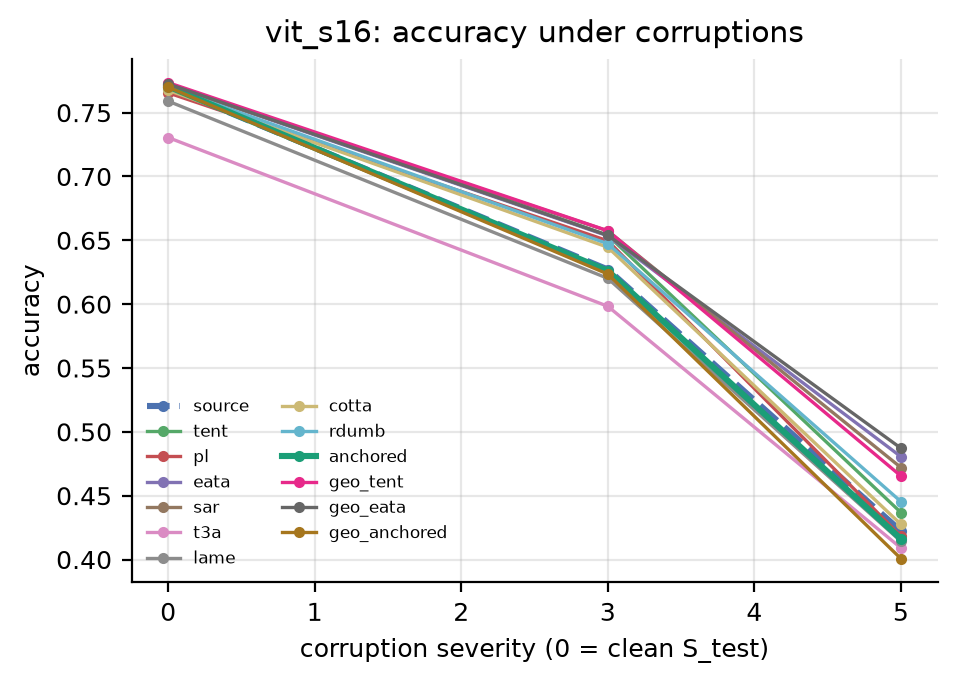

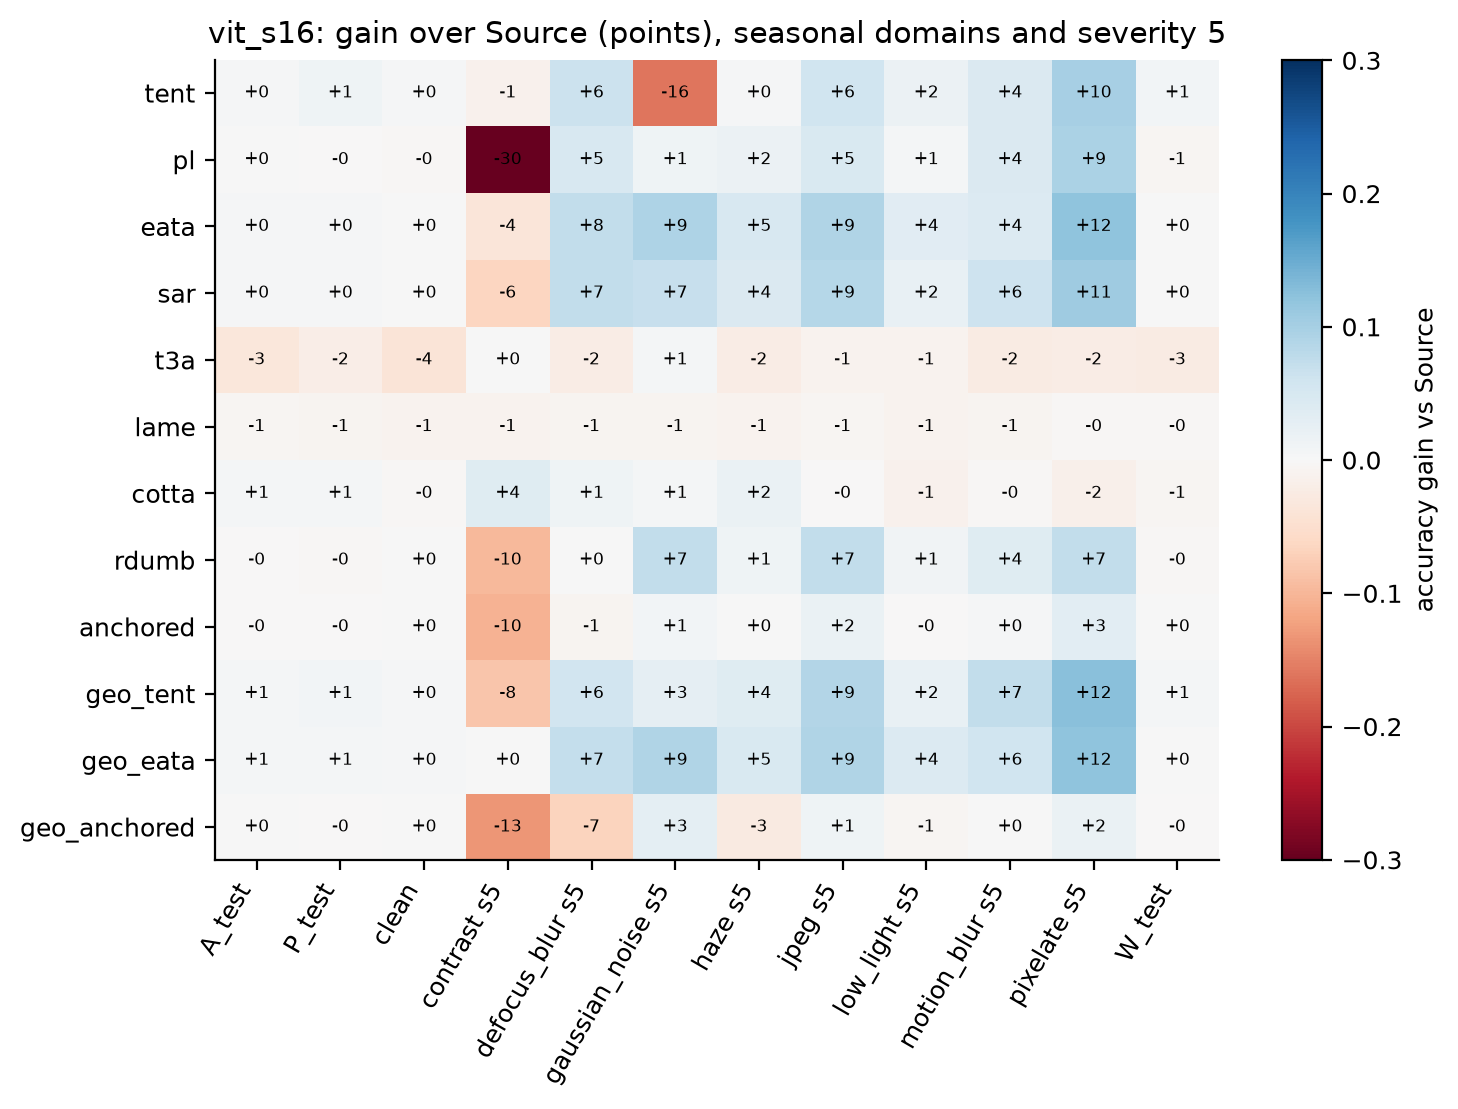

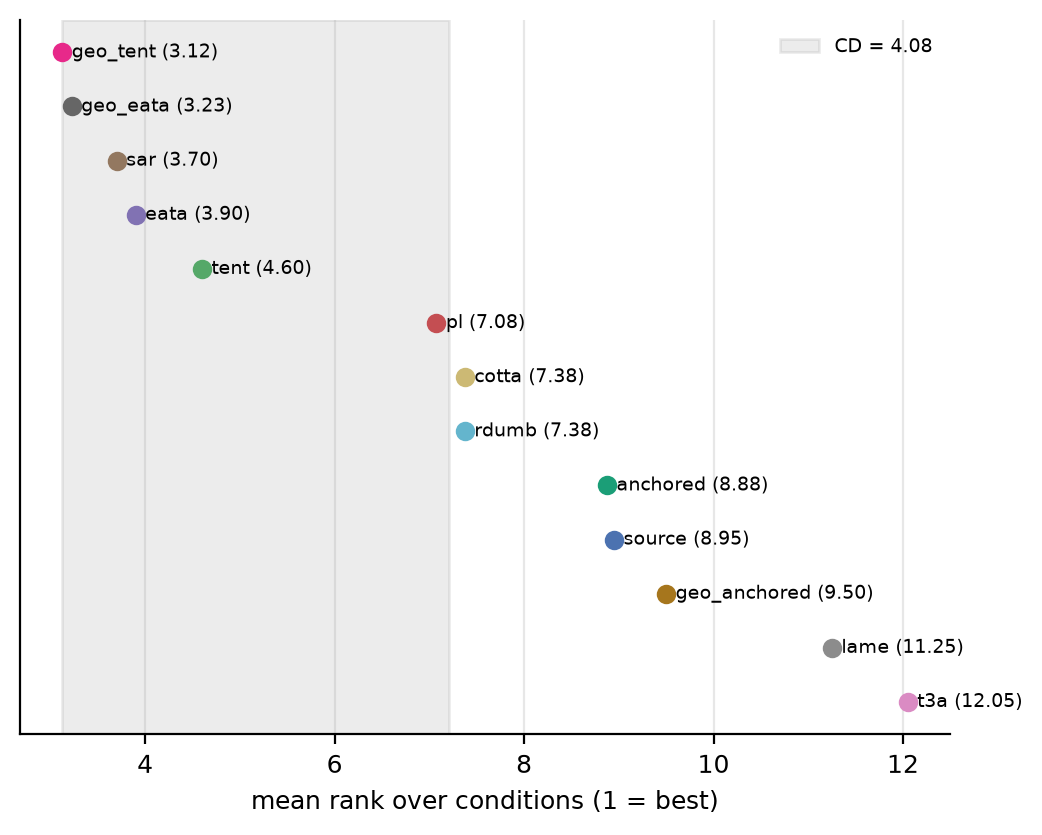

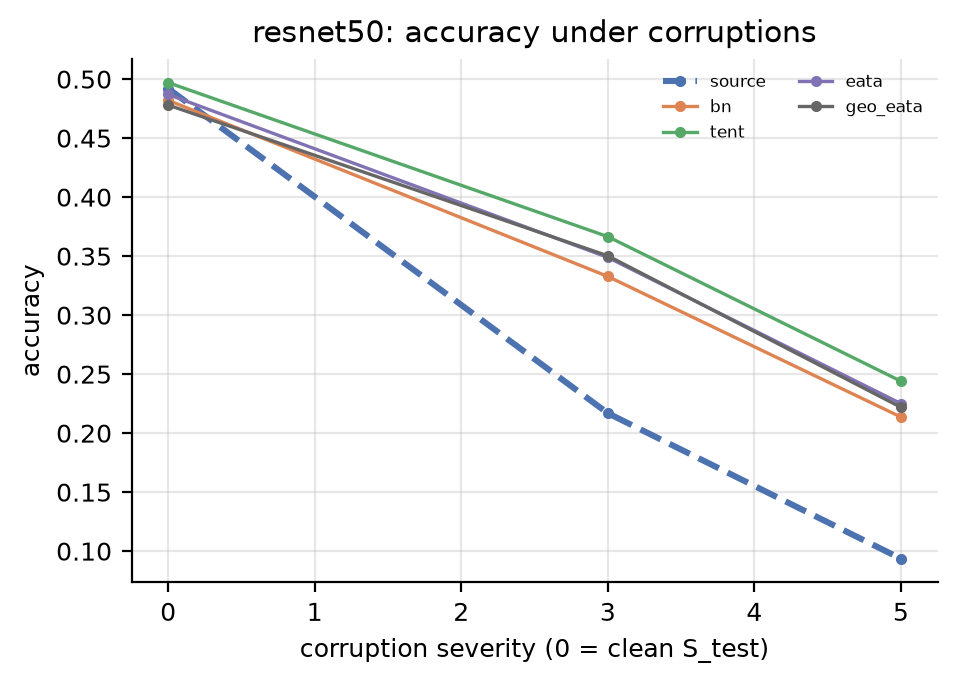

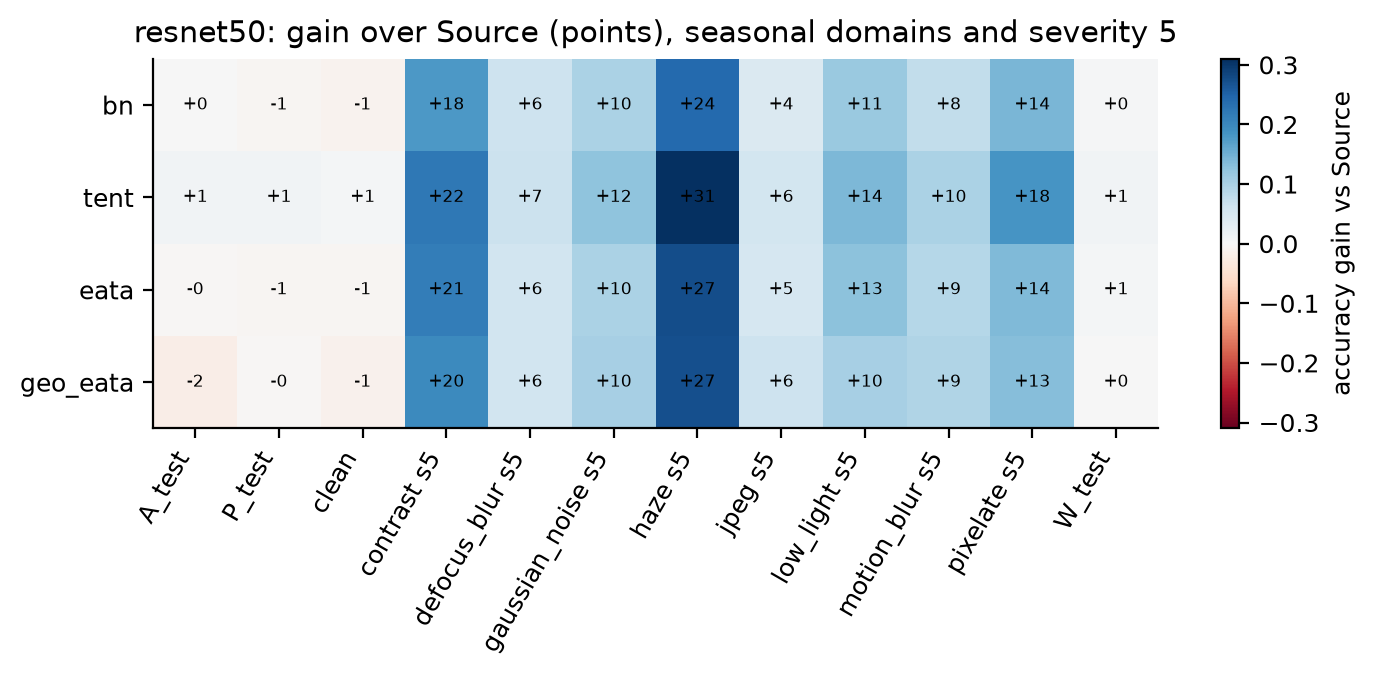

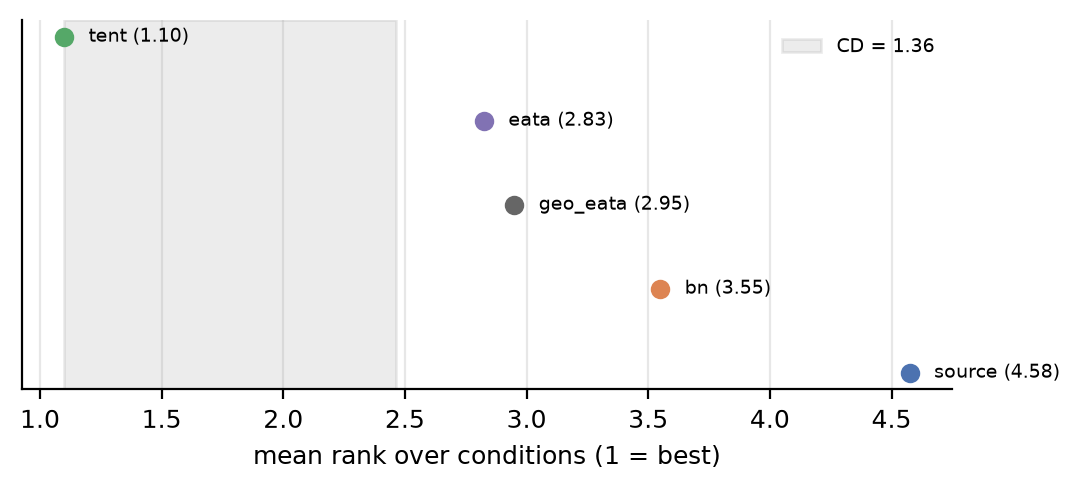

In [5]:
for bb in ['vit_s16', 'resnet50']:
    for n in ['severity', 'gain_heatmap', 'cd_diagram']:
        fig(f'06_tta_{bb}_{n}')